<center><h1>Linarez_Isabella_HW4</h1></center>
<br>
<br>

Name: Isabella Linarez
<br>
Github Username: isalinarez927
<br>
USC ID: 7543590784

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [112]:
import numpy as np
import statistics
import pandas as pd
import matplotlib.pyplot as plt
import os
import seaborn as sns
import warnings
import statsmodels.api as sm

from sklearn.metrics import ConfusionMatrixDisplay
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.exceptions import ConvergenceWarning
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore", category=PerfectSeparationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=PerfectSeparationWarning)
warnings.filterwarnings("ignore", message="The least populated class")

Get the AReM Data Set

In [113]:
root = "Data/AReM"
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13",
        "var_rss13", "avg_rss23", "var_rss23"]
records = []

for folder in sorted(os.listdir(root)):
    folder_path = os.path.join(root, folder)
    if not os.path.isdir(folder_path):
        continue
    for fname in sorted(os.listdir(folder_path)):
        if not fname.endswith(".csv"):
            continue
        df = pd.read_csv(os.path.join(folder_path, fname),
                         comment="#", header=None, names=cols,
                         sep=r"[,\s]+", engine="python", usecols=range(7))
        # some files were space-delimited and sep=r"[,\s]+" handles both
        num = int(fname.replace("dataset", "").replace(".csv", ""))
        records.append({"label": folder, "num": num, "df": df})


### (b) Splitting Data

In [114]:
train, test = [], []
for r in records:
    if r["label"].startswith("bending"):
        is_test = r["num"] in range(1,3)      
    else:
        is_test = r["num"] in range(1,4)      
    (test if is_test else train).append(r)

print(len(train), len(test))

69 19


### (c) Feature Extraction

In [115]:
def extract_features(df, l=1):
    signals = df.drop(columns="time")
    signals.columns = [str(i) for i in range(1, 7)]
    row = {}

    # split the 480 row positions into l equal(ish) groups
    for k, idx in enumerate(np.array_split(np.arange(len(signals)), l), start=1):
        chunk = signals.iloc[idx]
        stats = chunk.agg(["min", "max", "mean", "median", "std",
                           lambda s: s.quantile(0.25),
                           lambda s: s.quantile(0.75)])
        stats.index = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]

        for col in stats.columns:        # series number "1"–"6"
            for stat in stats.index:
                row[f"{stat}{col}_{k}"] = stats.loc[stat, col]

    return pd.DataFrame([row])


def build_features(records, l=1):
    rows = []
    for r in records:
        feat = extract_features(r["df"], l)
        feat["label"] = r["label"]
        feat["split"] = "test" if r in test else "train"
        rows.append(feat)
    out = pd.concat(rows, ignore_index=True)
    # Line below turns it into binary classification
    out["bending"] = out["label"].str.startswith("bending").astype(int)
    return out

features = build_features(records, 1)
features.shape


(88, 45)

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [116]:
print(features["bending"].value_counts())
print(len(cols))

bending
0    75
1    13
Name: count, dtype: int64
7


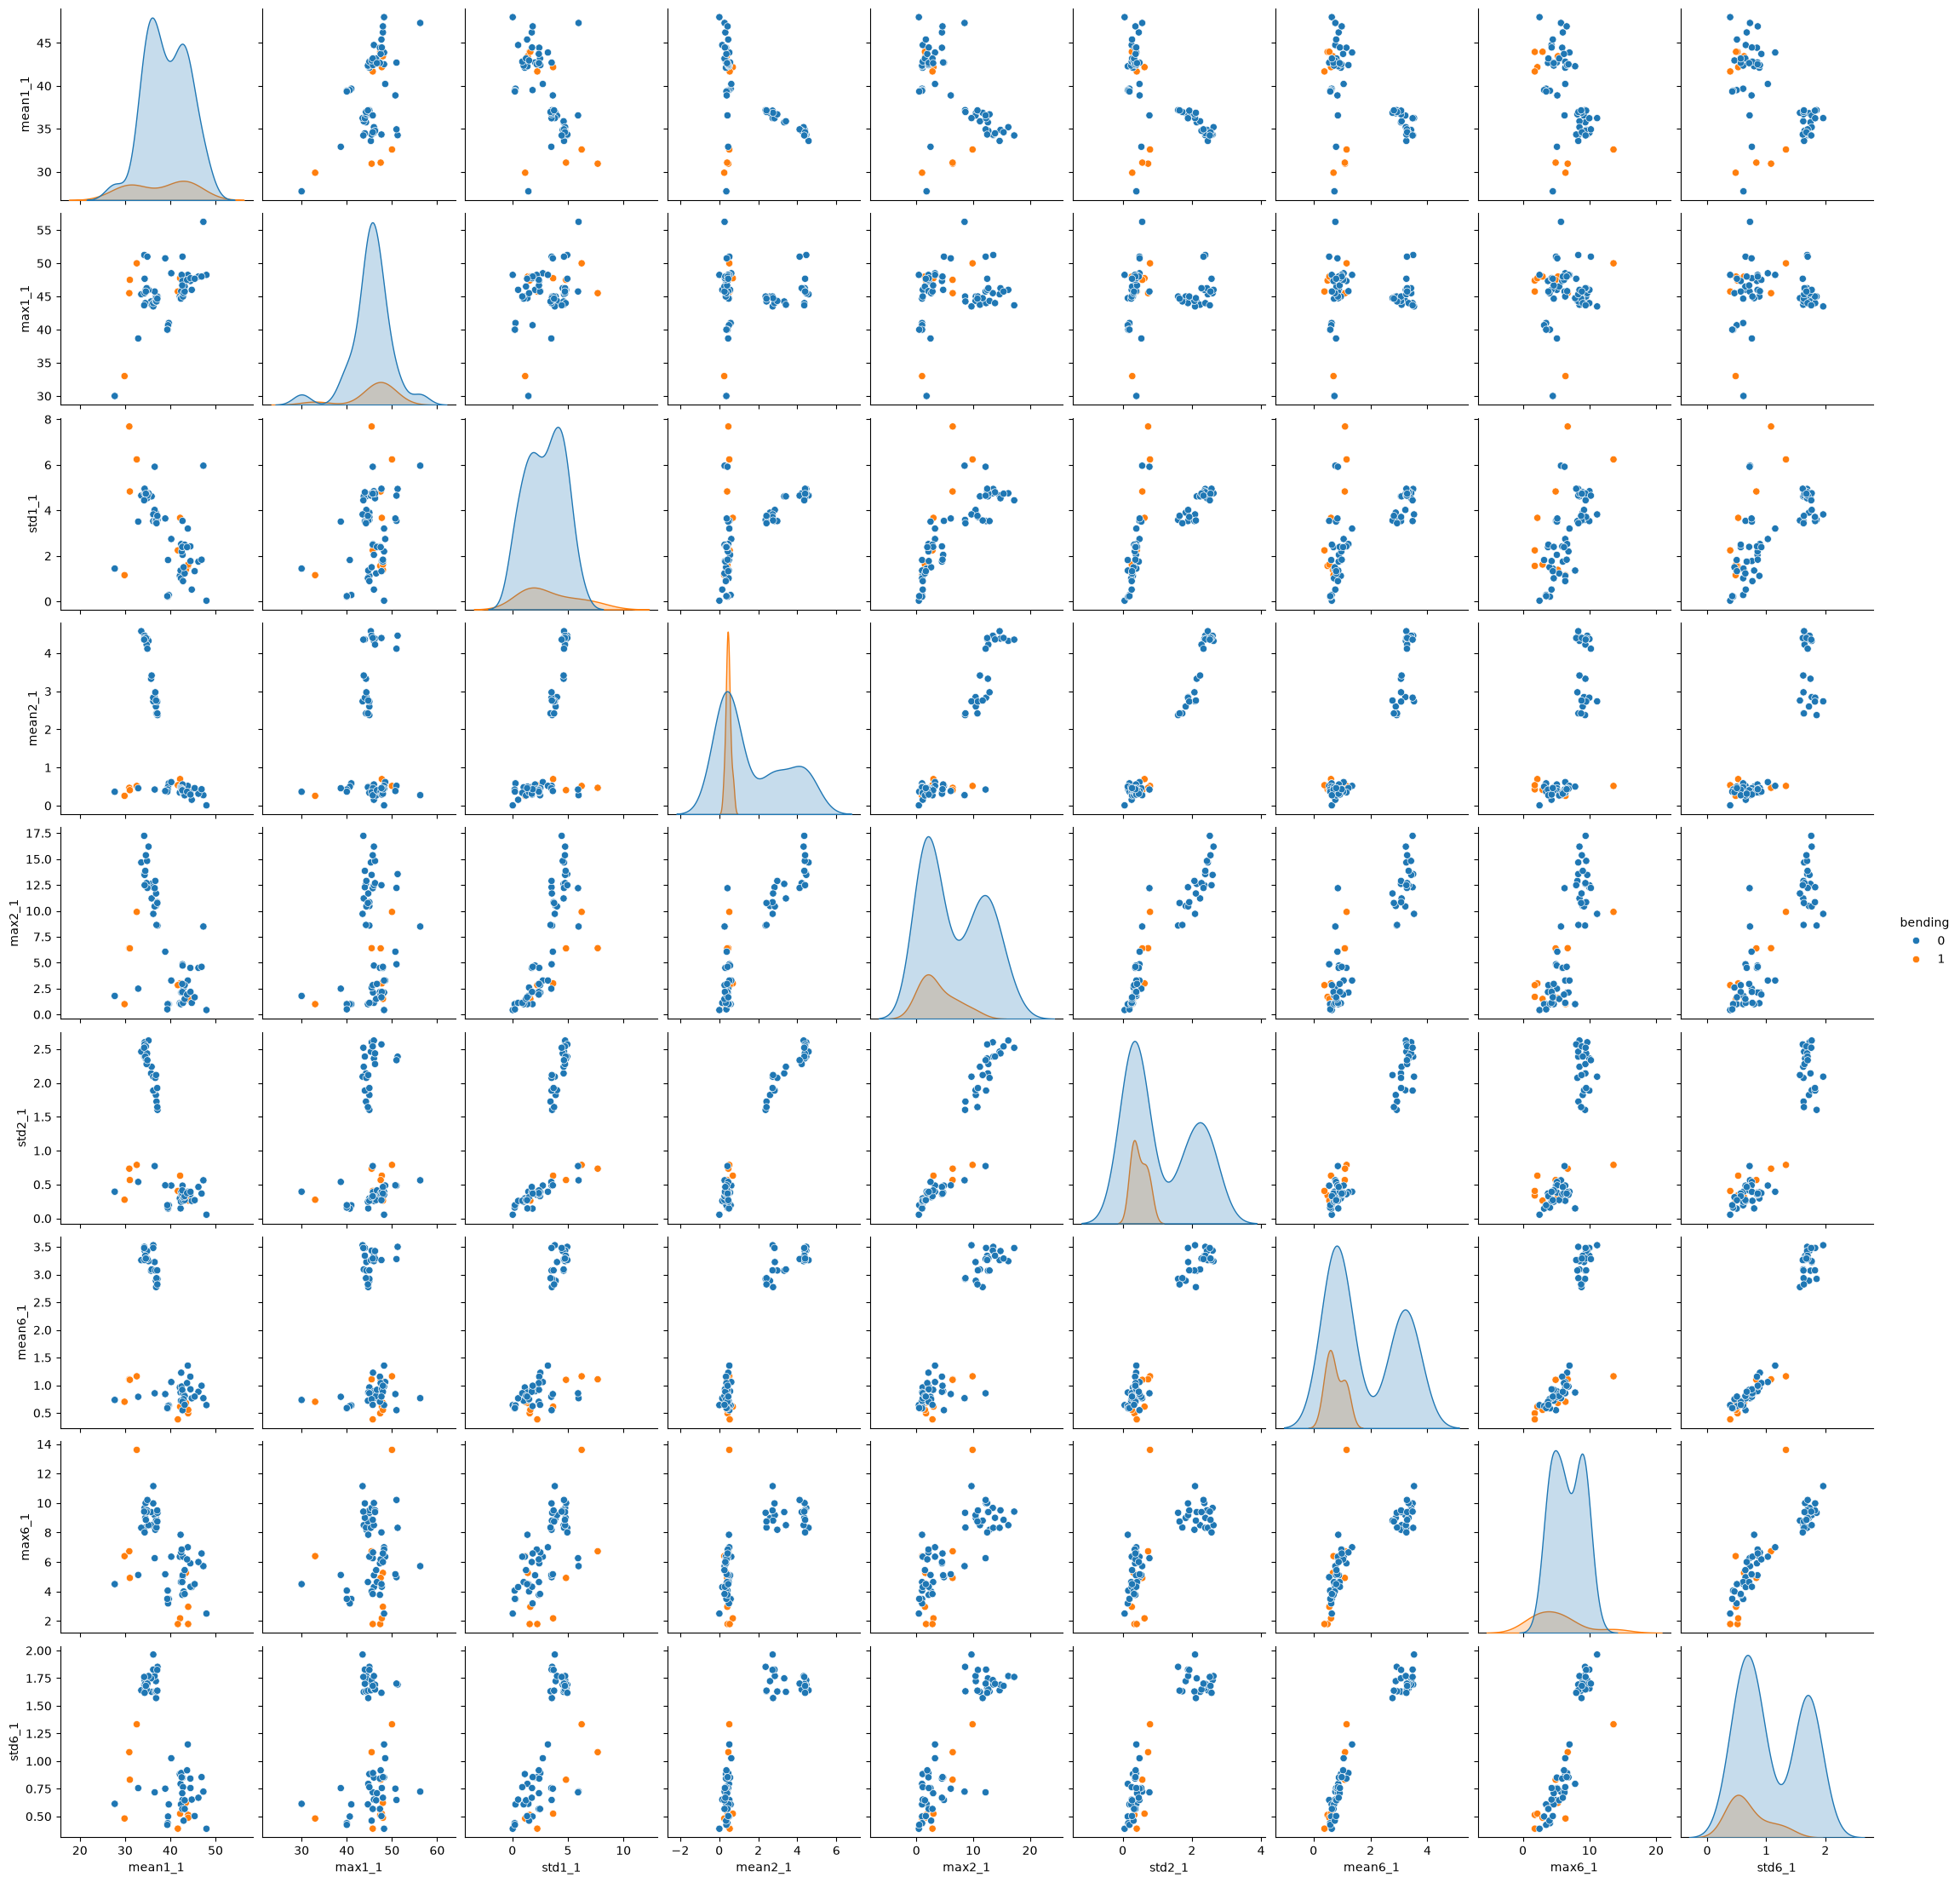

In [117]:
train1 = features[features["split"] == "train"]
cols = [f"{s}{i}_1" for i in [1, 2, 6] for s in ["mean", "max", "std"]]
sns.pairplot(train1, vars=cols, hue='bending');

#### ii. Splitted Plots

Splits each series into l pieces; names are {stat}{series}_{piece} (e.g. mean1_2 = series 1, piece 2). With l = 1 the whole series is one piece, so all names end in _1.

18


,min1_1,max1_1,mean1_1,median1_1,std1_1,1st_quart1_1,3rd_quart1_1,min2_1,max2_1,mean2_1,...,min6_2,max6_2,mean6_2,median6_2,std6_2,1st_quart6_2,3rd_quart6_2,label,split,bending
2,36.50,46.50,44.057167,44.50,1.556971,43.2500,45.00,0.0,1.50,0.381042,...,0.0,1.50,0.388333,0.00,0.478528,0.0000,0.71,bending1,train,1
3,33.75,47.75,43.278875,45.00,3.473355,42.0000,45.25,0.0,3.00,0.673292,...,0.0,2.18,0.586083,0.47,0.491873,0.0000,0.87,bending1,train,1
4,33.00,45.75,41.621208,42.33,3.118644,39.6525,44.25,0.0,2.83,0.623083,...,0.0,1.50,0.347500,0.43,0.363144,0.0000,0.50,bending1,train,1
5,39.00,48.00,44.117042,45.00,1.359836,43.5000,45.00,0.0,1.30,0.250042,...,0.0,4.06,0.543875,0.50,0.473445,0.4300,0.71,bending1,train,1
6,36.67,45.00,43.486208,43.71,1.281976,42.3300,44.50,0.0,1.30,0.378667,...,0.0,2.96,0.585750,0.50,0.487918,0.4225,0.83,bending1,train,1


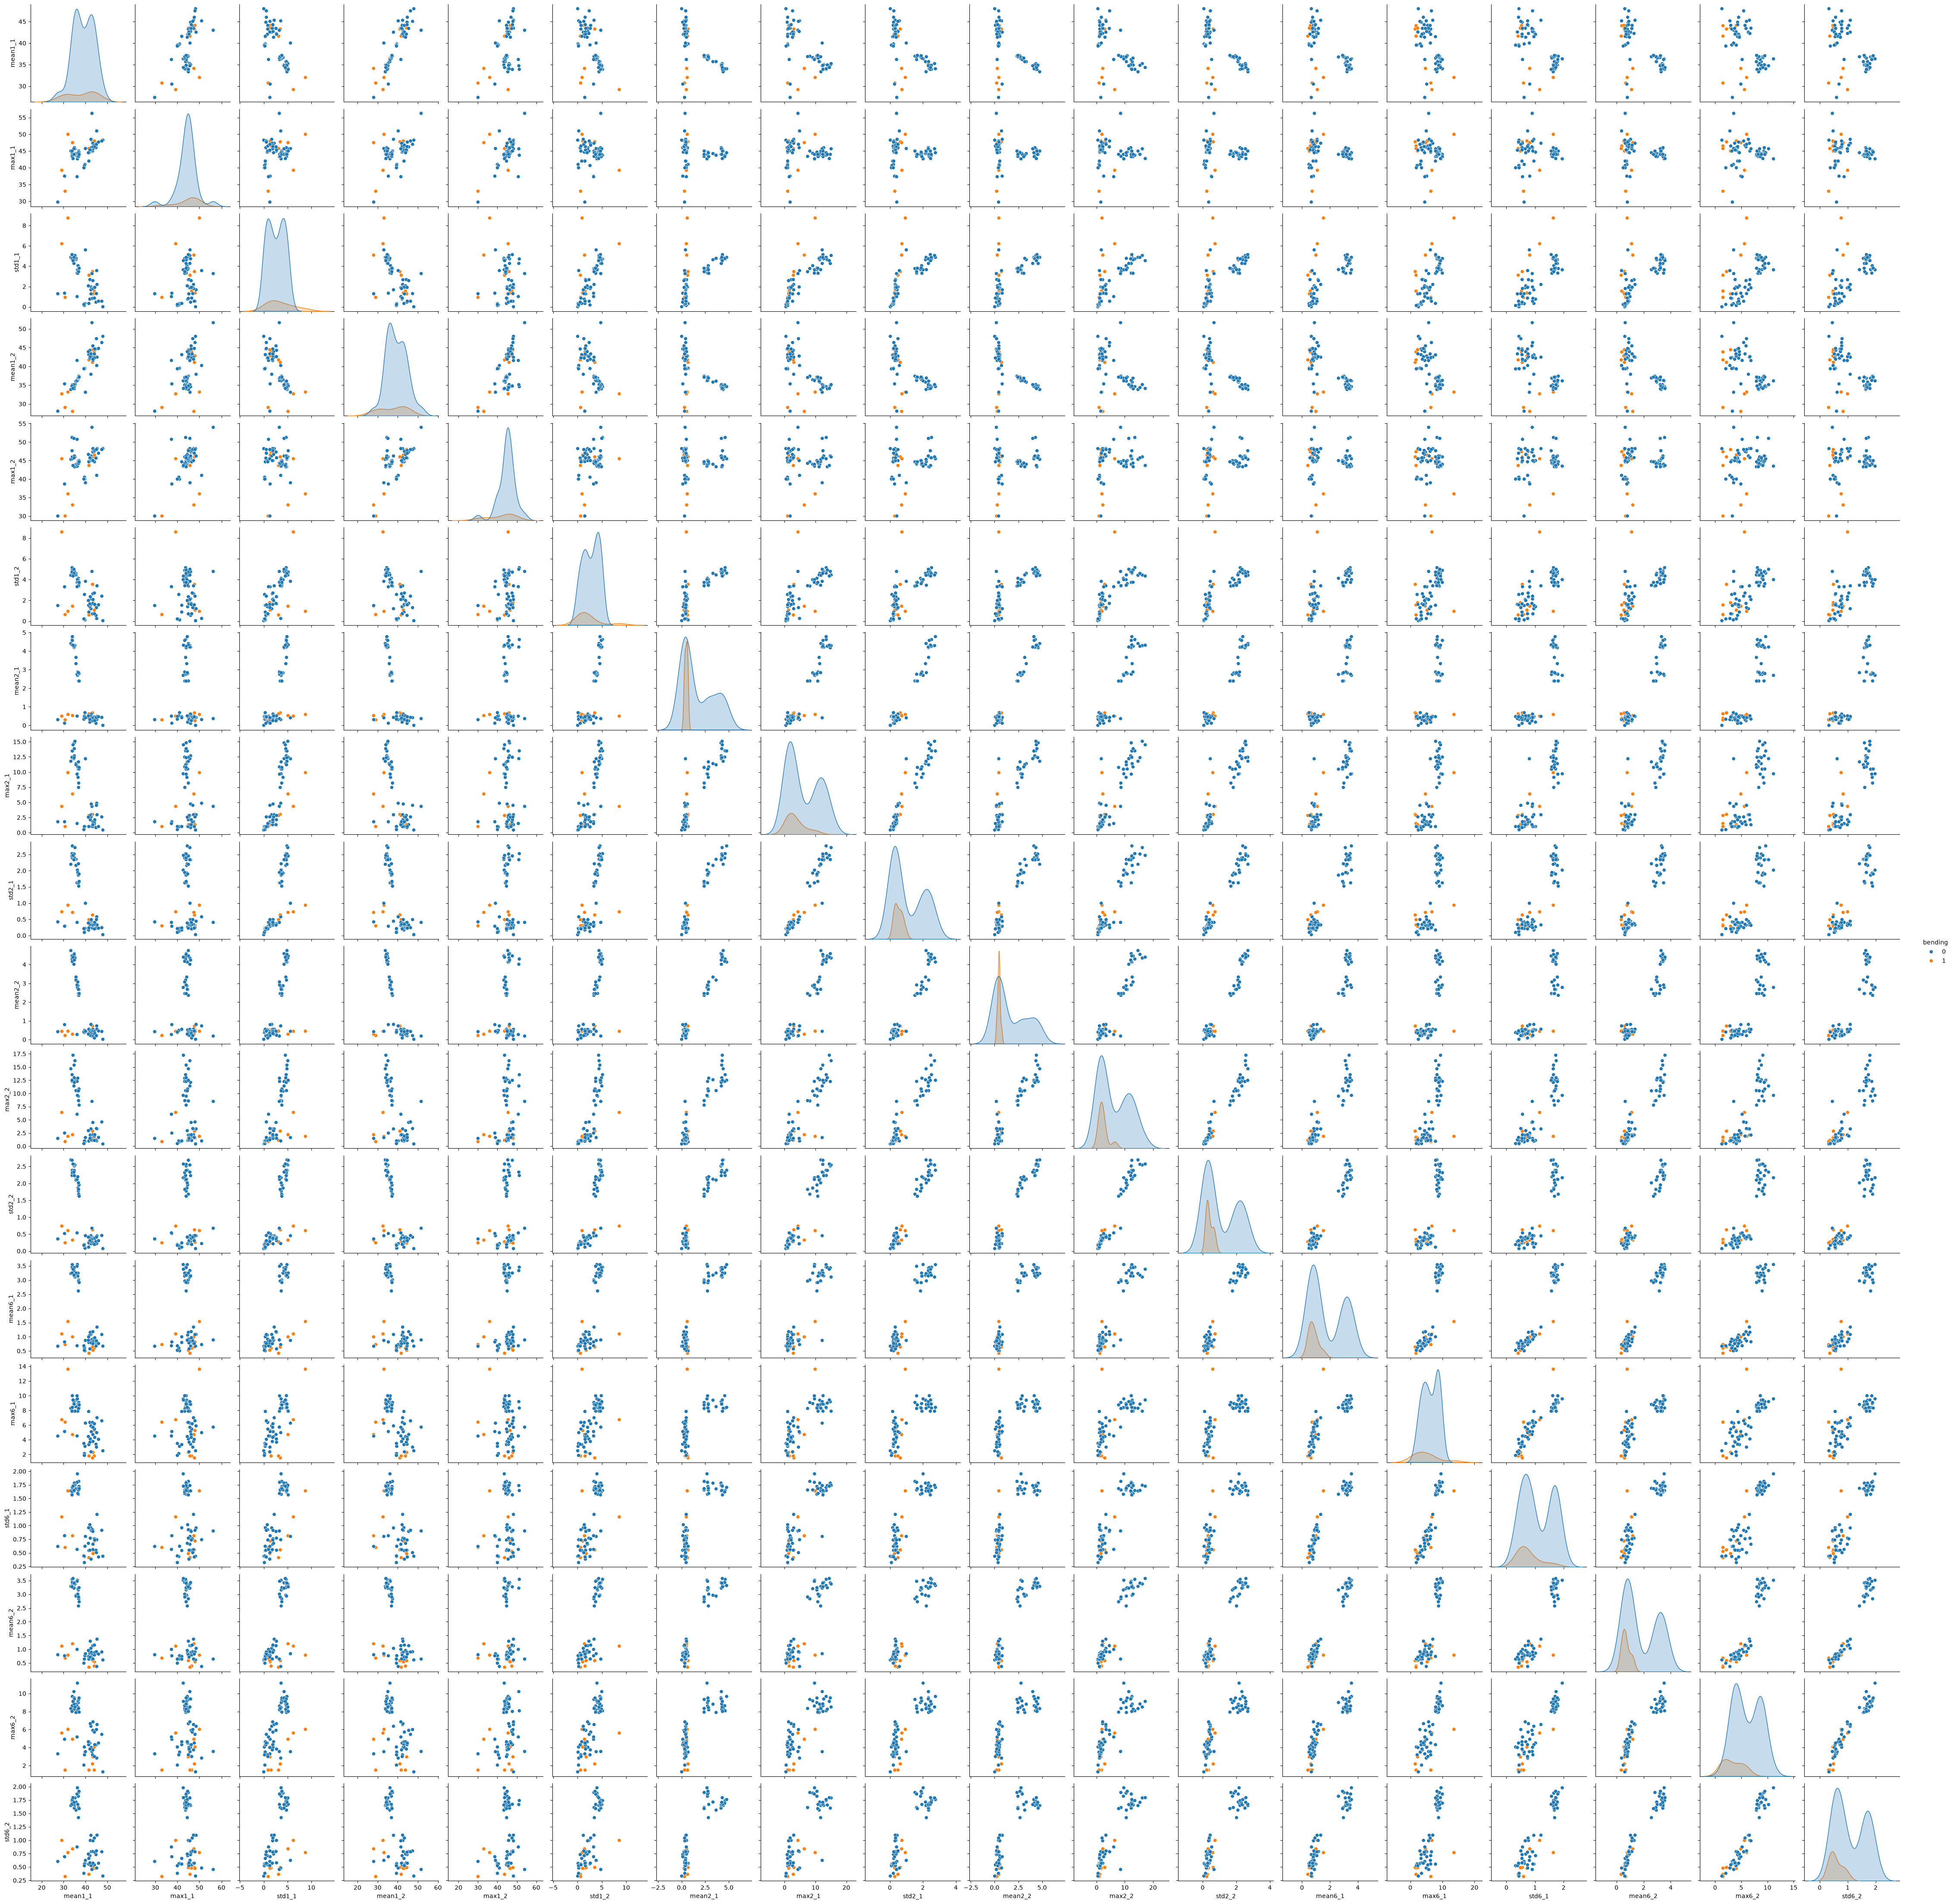

In [118]:
features2 = build_features(records, 2)
# Now you are splitting the time series into 2
train2 = features2[features2["split"] == "train"]
cols2 = [f"{s}{i}_{k}" for i in [1, 2, 6] for k in [1, 2] for s in ["mean", "max", "std"]]
print(len(cols2))
sns.pairplot(train2, vars=cols2, hue="bending");
train2.head()

**Do you see any considerable diﬀerence in the results with those of 2(a)i?**

No considerable difference compared with 2ai. Splitting each time series into two still shows the same overall pattern. The bending recordings sit inside the cluster of other stationary activities (lying, sitting, standing) in most feature pairs, and recordings of cycling and walking remain clearly separated from everything. 

As in 2ai, the mean of time series 1 still separates some of the bending recordings (likely bending2) from the rest. Splitting into halves doesn't separate bending any better, because each half looks like the whole recording.

mean1_1 & mean1_2 look nearly identical. They nearly fall on a diagonal line, because the first and second minute of a recording come from the same activity 


#### iii. Time Series Segments

In [119]:
# Setting up features DF with 20 splits
features20 = build_features(records, 20)
train20 = features20[features20["split"] == "train"]
train20.head()

,min1_1,max1_1,mean1_1,median1_1,std1_1,1st_quart1_1,3rd_quart1_1,min2_1,max2_1,mean2_1,...,min6_20,max6_20,mean6_20,median6_20,std6_20,1st_quart6_20,3rd_quart6_20,label,split,bending
2,40.0,45.00,43.513750,44.040,1.627673,42.1875,45.0000,0.0,0.87,0.387500,...,0.0,1.30,0.183333,0.000,0.338586,0.00,0.43,bending1,train,1
3,36.0,47.50,44.097083,45.000,3.286239,43.3350,46.5000,0.0,3.00,0.651250,...,0.0,1.30,0.350000,0.430,0.387545,0.00,0.44,bending1,train,1
4,36.0,44.50,41.563750,42.000,2.133087,41.0000,42.5625,0.0,1.22,0.464583,...,0.0,1.00,0.307500,0.430,0.319514,0.00,0.50,bending1,train,1
5,41.0,46.75,44.756667,45.000,1.237226,44.8750,45.0000,0.0,1.30,0.288750,...,0.0,4.06,1.074583,0.830,0.954108,0.47,1.24,bending1,train,1
6,41.5,44.25,42.951250,43.165,0.801967,42.2475,43.5425,0.0,0.94,0.483333,...,0.0,1.73,0.671250,0.665,0.473721,0.43,0.94,bending1,train,1


In [120]:
l_acc_cv_score = {}

for l in range (1,21):
    featuresL = build_features(records, l)
    trainL = featuresL[featuresL["split"] == "train"]

    X = trainL.drop(columns=["label", "split", "bending"])
    y = trainL["bending"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Using  5-fold cross-validation
    for num_features in range (1,11): 
        #set the p to this bc more features than that is excessive for 55 training recordings
        lp_tuple = (l , num_features)
        fold_scores = []

        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
            X_train, y_train  = X.iloc[train_idx],  y.iloc[train_idx]
            X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
            # step=0.1 removes 10% of the original count per round 
            rfe = RFE(estimator=LogisticRegression(C=1e9, max_iter=1000), n_features_to_select= num_features, step=.1)
            rfe.fit(X_train, y_train)

            X_train_selected = rfe.transform(X_train)
            X_val_selected = rfe.transform(X_val)

            model = LogisticRegression(C=1e9, max_iter=1000) # better practice to use inside loop
            model.fit(X_train_selected, y_train)
            preds = model.predict(X_val_selected)
            acc = accuracy_score(y_val, preds)
            fold_scores.append(acc)

            # print(f"L: {l}  Fold {fold}: accuracy = {acc:.3f}")
        
        l_acc_cv_score[lp_tuple] = np.mean(fold_scores)

    # print(f'l = {l}    , p = {num_features}  ,  CV accuracy: {l_acc_cv_score[lp_tuple]}')

In [121]:
l_p_cv_df = pd.DataFrame([(l, p, acc) for (l, p), acc in l_acc_cv_score.items()], columns=["l", "p", "cv_acc"])
l_p_cv_df.sort_values(["cv_acc", "l", "p"], ascending=[False, True, True]).head(15)

,l,p,cv_acc
5,1,6,1.000000
7,1,8,1.000000
8,1,9,1.000000
9,1,10,1.000000
16,2,7,0.985714
23,3,4,0.985714
49,5,10,0.985714
184,19,5,0.985714
4,1,5,0.984615
6,1,7,0.984615


**Best selection of features:**
Best (l,p) is (1,6). l is how many pieces each time series is split into and p is how many features the model actually keeps.

**Wrong way to perform cross-validation:** Run feature selection on all 69 training recordings first to pick the best p features before using 5-fold CV only to score a logistic regression on those already-chosen features. The problem is that RFE has already looked at every recording's label, including the ones that are considered validation folds. The validation data leaks into the feature selection, so the CV accuracy comes out higher.

**Right way to perform cross-validation:**  Put feature selection as part of the model and repeat it inside every fold. For each (l, p) pair, in each of the 5 folds, RFE is fit using four of the five folds for training, and the selected model is scored on the held-out validation part (one of the five folds). That one fold had no influence on which features were chosen. The CV accuracy is the mean over the 5 folds, and the (l, p) pair with the highest CV accuracy is selected.

Stratified 5-fold CV was used to handle class imbalance between bending to non-bending recordings, and the same random_state across all l so every (l, p) pair is evaluated on identical folds. 

Order was considered by choosing the smallest l, then the smallest p, giving (l, p) = (1, 6).

#### iv. Confusion Matrix

In [122]:
# full dataset of training, where l = 1
X = train1.drop(columns=["label", "split", "bending"])
# binary evalutation on y (answer key)
y = train1["bending"]

# This sets up recursive feature elimination, but doesn't run it yet. (p = 6)
rfe_optimal = RFE(estimator=LogisticRegression(C=1e9, max_iter=1000), n_features_to_select= 6, step=.1)
rfe_optimal.fit(X, y)

# support_ - Using it to index X.columns pulls out only the names marked True.
selected = X.columns[rfe_optimal.support_]
selected_features = selected.tolist()
print(selected_features)
print(rfe_optimal.estimator_.coef_)   # part iv model


['3rd_quart1_1', 'min5_1', 'max5_1', 'mean5_1', '1st_quart5_1', 'max6_1']
[[-2.31081427  1.27140379  2.01805335  0.88963232  0.989703   -1.3797961 ]]


**Refitting the final model.** Cross-validation selected (l, p) = (1, 6), so I refit RFE on all 69 training recordings using whole-series features (l = 1) and kept the 6 best features. I used the same settings as in CV (C = 1e9 to remove the L2 penalty, step = 0.1). The selected features are mostly from time series 5 (avg_rss23), the signal between the two ankles.

In [123]:
pred_optimal = rfe_optimal.predict(X)
cm = confusion_matrix(y, pred_optimal)
print(cm)

y_probs = rfe_optimal.predict_proba(X)[:,1]

fpr, tpr, thresholds = roc_curve(y, y_probs)
roc_auc = auc(fpr, tpr)

print(f"AUC Score: {roc_auc:.4f}")

[[60  0]
 [ 0  9]]
AUC Score: 1.0000


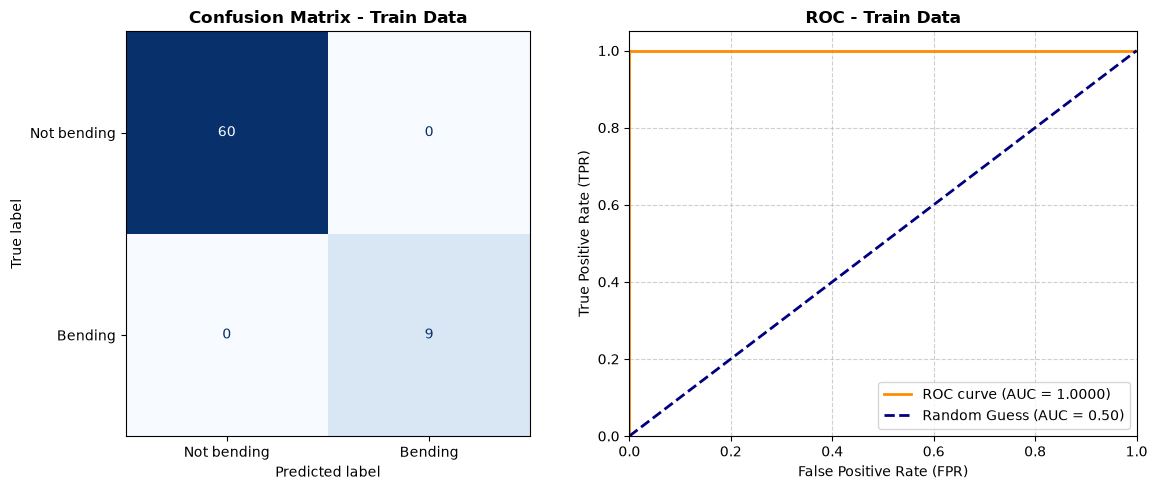

In [124]:
fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

# Left: confusion matrix
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not bending", "Bending"]).plot(
    ax=ax_cm, cmap="Blues", colorbar=False
)
ax_cm.set_title("Confusion Matrix - Train Data", fontsize=12, fontweight="bold")

# Right: ROC curve
ax_roc.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
ax_roc.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess (AUC = 0.50)")
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.set_title("ROC - Train Data", fontsize=12, fontweight="bold")
ax_roc.legend(loc="lower right", fontsize=10)
ax_roc.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

The training ROC curve reaches the top-left corner and AUC = 1.0, meaning the predicted probabilities rank every bending recording above every non-bending one.

In [125]:
X_selected = train1[selected_features]
X_selected = sm.add_constant(X_selected) # Adds the intercept (const) column

stats_model = sm.Logit(train1["bending"], X_selected).fit()

parameters_df = pd.DataFrame({ 'Beta Coefficient (βi)': stats_model.params, 'p-value': stats_model.pvalues })

parameters_df

         Current function value: 0.000000
         Iterations: 35


/opt/anaconda3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Beta Coefficient (βi),p-value
const,16.767282,1.000000
3rd_quart1_1,-8.104689,0.999995
min5_1,4.066959,0.999996
max5_1,6.903936,0.999995
mean5_1,1.911272,1.000000
1st_quart5_1,4.034388,0.999999
max6_1,-3.831991,0.999996


#### v. Test Set

In [126]:
test1 = features[features["split"] == "test"]

X_test = test1.drop(columns=["split", "bending", "label"])  
y_test = test1["bending"]

test_preds = rfe_optimal.predict(X_test)
test_acc   = accuracy_score(y_test, test_preds)

print("Test accuracy:", test_acc)
print(confusion_matrix(y_test, test_preds))
print("CV accuracy:", l_acc_cv_score[(1, 6)])

Test accuracy: 1.0
[[15  0]
 [ 0  4]]
CV accuracy: 1.0


On the 19 test recordings, this classifier (where l = 1, and p = 6) achieved a test accuracy of 1.0 meaning it correctly classified all non-bending (15/15) and bending (4/4) recordings. Since the test accuracy is the same as the CV accuracy, it shows that the cross-validation estimate was a reliable prediction of performance on unseen data. Note that the test set is small, so one misclassification would lower the accuracy significantly; an acurracy score should be interpreted with that in mind

#### vi. Separation

Yes, the classes are well separated, and that causes instability. The model classifies training data perfectly: confusion matrix with no errors, AUC = 1.0 and and statsmodels raised a PerfectSeparationWarning. Because the training classes are perfectly separable, maximum likelihood did not converge: the reported βs are where the optimizer stopped (the iteration limit). Note that sklearn and statsmodels give different coefs for the same model, and the p-values (≈ 1) come from inflated standard errors rather than a lack of importance.

#### vii. Imbalance

In [127]:
cases = train1[train1['bending']==1]
controls = train1[train1['bending']==0]

sampled_controls = controls.sample(n=9, random_state=42) 
cc_data = pd.concat([cases, sampled_controls])

# 2. fit on the sample, same 6 features
X_cc = cc_data[selected_features]
y_cc = cc_data['bending']
cc_model = LogisticRegression(C=1e9, max_iter=1000)
cc_model.fit(X_cc, y_cc)

# 3. adjust the intercept
pi = train1["bending"].mean()   # 9/69 NOTE: the mean works bc its binary classification
pi_tilde = y_cc.mean()          # 9/18
adjustment = np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
cc_model.intercept_ = cc_model.intercept_ + adjustment

# 4. evaluate on the full training set: confusion matrix, ROC, AUC
X_full = train1[selected_features]
y_full = train1["bending"]

pred_control = cc_model.predict(X_full)
cm_cc = confusion_matrix(y_full, pred_control)
# print(cm_cc)

y_probs_control = cc_model.predict_proba(X_full)[:,1]

fpr_cc, tpr_cc, thresholds_cc = roc_curve(y_full, y_probs_control)
roc_auc_cc = auc(fpr_cc, tpr_cc)

print(f"AUC Score: {roc_auc_cc:.4f}")

print("Adjustment:", adjustment)
print("Adjusted intercept:", cc_model.intercept_)
print("Coefficients:", cc_model.coef_)

# compare probabilities: part iv model vs. case-control model
# print(rfe_optimal.predict_proba(X)[:5, 1])
# print(cc_model.predict_proba(X_full)[:5, 1])

AUC Score: 1.0000
Adjustment: -1.8971199848858813
Adjusted intercept: [-1.96335769]
Coefficients: [[-1.95785459  0.5630137   1.87904146  0.79484122  1.00112059 -1.66517311]]


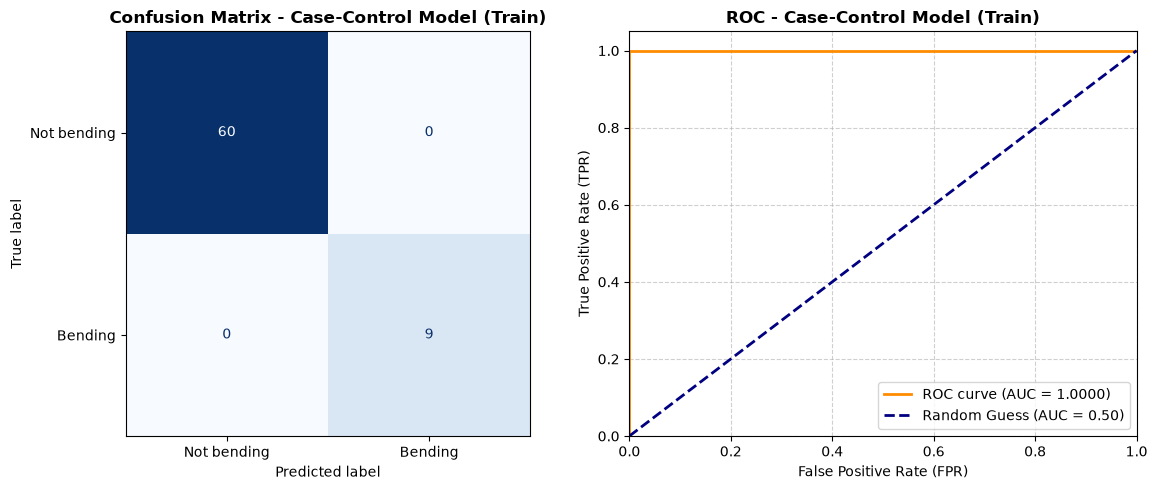

In [128]:
# plot side by side
fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix=cm_cc, display_labels=["Not bending", "Bending"]).plot(
    ax=ax_cm, cmap="Blues", colorbar=False
)
ax_cm.set_title("Confusion Matrix - Case-Control Model (Train)", fontsize=12, fontweight="bold")

ax_roc.plot(fpr_cc, tpr_cc, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc_cc:.4f})")
ax_roc.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess (AUC = 0.50)")
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10)
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10)
ax_roc.set_title("ROC - Case-Control Model (Train)", fontsize=12, fontweight="bold")
ax_roc.legend(loc="lower right", fontsize=10)
ax_roc.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [129]:
lc_score = {}
c_values_10000 = np.logspace(-2, 4, 13)   # 0.01 up to 10,000

for l in range (1,21):
    featuresL = build_features(records, l)
    trainL = featuresL[featuresL["split"] == "train"]

    X = trainL.drop(columns=["label", "split", "bending"])
    y = trainL["bending"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Using  5-fold cross-validation
    for c in c_values_10000: 
        lc_tuple = (l , c)
        fold_scores = []

        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
            X_train, y_train  = X.iloc[train_idx],  y.iloc[train_idx]
            X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from train only
            X_val_scaled   = scaler.transform(X_val)         # apply them to val (no fitting!)

            model = LogisticRegression(l1_ratio=1, solver="liblinear", C=c, random_state=42)
            model.fit(X_train_scaled, y_train)

            
            preds = model.predict(X_val_scaled)
            acc = accuracy_score(y_val, preds)
            fold_scores.append(acc)

        
        lc_score[lc_tuple] = np.mean(fold_scores)

    

In [130]:
lc_score_df = pd.DataFrame([(l, c, acc) for (l, c), acc in lc_score.items()], columns=["l", "c", "cv_acc"])
# l_p_cv_df.sort_values(by="cv_acc")
lc_score_df.sort_values(["cv_acc", "l", "c"], ascending=[False, True, True]).head(15)

,l,c,cv_acc
12,1,10000.000000,0.985714
5,1,3.162278,0.971429
10,1,1000.000000,0.971429
11,1,3162.277660,0.971429
19,2,10.000000,0.971429
125,10,100.000000,0.971429
126,10,316.227766,0.971429
147,12,1.000000,0.971429
148,12,3.162278,0.971429
149,12,10.000000,0.971429


Best (l, C) = (1, 10,000) with CV accuracy 0.986, using smallest l then smallest C as the tiebreaker. I tested 13 values of C spaced evenly on a log scale from 0.01 to 10,000.

In [131]:
feats1 = build_features(records, 1)
tr1 = feats1[feats1["split"] == "train"]
X1 = tr1.drop(columns=["label", "split", "bending"])
y1 = tr1["bending"]

check = LogisticRegression(l1_ratio=1, solver="liblinear", C=0.1, random_state=42)
check.fit(StandardScaler().fit_transform(X1), y1)
print(np.sum(check.coef_ == 0), "of", check.coef_.size, "coefficients are exactly zero")
print(X1.columns[check.coef_[0] != 0])

41 of 42 coefficients are exactly zero
Index(['max5_1'], dtype='str')


#### ii. Comparison

**Performance:** Variable selection with RFE performed slightly better with (l, p) = (1, 6), reaching a CV accuracy of 1.0 compared with 0.986 for L1-penalized logistic regression at (l, C) = (1, 10,000). The difference amounts to one recording out of 69, so it is safe to say that the two methods perform about the same on this data. L1's suggested regularization did not add much here given that the best C was the max of the tested range (a very weak penalty),

**Ease of implementation:** L1 is easier to implement since it selects features and fits the model in one step and only has C to tune. The p-value/RFE approach requires a separate selection step and a choice of p. L1 is also more stable: the penalty keeps the coefficients fixed even when the classes are perfectly separable, whereas the p-values from unpenalized logistic regression were unreliable (≈ 1) because maximum likelihood did not converge.

### (c) Multi-class Classification (The Realistic Case)

In [132]:
lc_multi_score = {}

c_values_10000 = np.logspace(-2, 4, 13)   # 0.01 up to 10,000
for l in range (1,21):
    print(f"starting l = {l}")
    featuresL = build_features(records, l)
    trainL = featuresL[featuresL["split"] == "train"]

    X = trainL.drop(columns=["label", "split", "bending"])
    y = trainL["label"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # Using  5-fold cross-validation
    for c in c_values_10000: 
        lc_tuple = (l , c)
        fold_scores = []

        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
            X_train, y_train  = X.iloc[train_idx],  y.iloc[train_idx]
            X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from train only
            X_val_scaled   = scaler.transform(X_val)         # apply them to val (no fitting!)

            model = LogisticRegression(l1_ratio=1, solver="saga", C=c, max_iter=5000, random_state=42)
            model.fit(X_train_scaled, y_train)

            
            preds = model.predict(X_val_scaled)
            acc = accuracy_score(y_val, preds)
            fold_scores.append(acc)

        
        lc_multi_score[lc_tuple] = np.mean(fold_scores)

    

starting l = 1
starting l = 2
starting l = 3
starting l = 4
starting l = 5
starting l = 6
starting l = 7
starting l = 8
starting l = 9
starting l = 10
starting l = 11
starting l = 12
starting l = 13
starting l = 14
starting l = 15
starting l = 16
starting l = 17
starting l = 18
starting l = 19
starting l = 20


In [133]:
lc_multi_df = pd.DataFrame( [(l, c, acc) for (l, c), acc in lc_multi_score.items()],
    columns=["l", "c", "cv_acc"]
)
lc_multi_df.sort_values(["cv_acc", "l", "c"], ascending=[False, True, True]).head(15)

,l,c,cv_acc
18,2,3.162278,0.914286
19,2,10.000000,0.914286
21,2,100.000000,0.914286
22,2,316.227766,0.914286
23,2,1000.000000,0.914286
5,1,3.162278,0.913187
17,2,1.000000,0.900000
20,2,31.622777,0.900000
24,2,3162.277660,0.900000
25,2,10000.000000,0.900000


Best (l, C) = (2, 3.16) with CV accuracy 0.914 (same tiebreaker and C grid)

Report your test error. Research how confusion matrices and ROC curves are defined for multiclass classification and show them for this problem if possible.

Test error: 0.1578947368421053


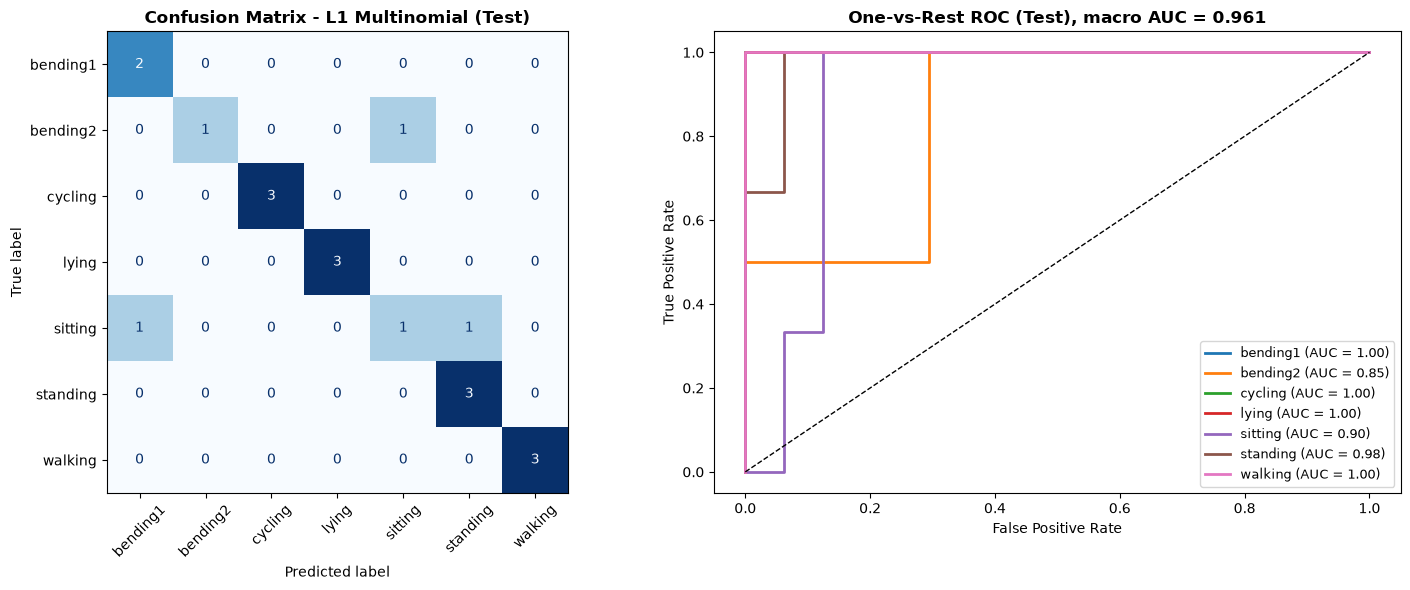

In [134]:
test2 = features2[features2["split"] == "test"]

X_train2 = train2.drop(columns=["label", "split", "bending"])
y_train2 = train2["label"]
X_test2 = test2.drop(columns=["label", "split", "bending"])
y_test2 = test2["label"]

scaler = StandardScaler()
X_train2_s = scaler.fit_transform(X_train2)
X_test2_s = scaler.transform(X_test2)

multi_final = LogisticRegression(l1_ratio=1, solver="saga", C=10**0.5, max_iter=5000, random_state=42)
multi_final.fit(X_train2_s, y_train2)

# test error
test_preds = multi_final.predict(X_test2_s)
print("Test error:", 1 - accuracy_score(y_test2, test_preds))

# one-vs-rest ROC
classes = multi_final.classes_
y_te_bin = label_binarize(y_test2, classes=classes)   # one 0/1 column per activity
probs = multi_final.predict_proba(X_test2_s)          # one probability column per activity

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay(confusion_matrix(y_test2, test_preds, labels=classes),
                       display_labels=classes).plot(ax=ax_cm, cmap="Blues", colorbar=False, xticks_rotation=45)
ax_cm.set_title("Confusion Matrix - L1 Multinomial (Test)", fontweight="bold")

aucs = []
for i, cls in enumerate(classes):
    fpr_i, tpr_i, _ = roc_curve(y_te_bin[:, i], probs[:, i])
    auc_i = auc(fpr_i, tpr_i)
    aucs.append(auc_i)
    ax_roc.plot(fpr_i, tpr_i, lw=2, label=f"{cls} (AUC = {auc_i:.2f})")

ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title(f"One-vs-Rest ROC (Test), macro AUC = {np.mean(aucs):.3f}", fontweight="bold")
ax_roc.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

**Test error:** 0.158 (3/19 test recordings misclassified), compared with a CV error of 0.086. The gap is about one or two recordings. Expected given the small test set.

All errors involve the stationary activities: one sitting recording was predicted as bending1 and one as standing, and one bending2 recording was predicted as sitting. Per-class AUCs are 1.00 except sitting (0.90), bending2 (0.85), and standing (0.98).

**Multiclass confusion matrix:** For K classes it is a K × K table. Correct predictions lie on the diagonal; off-diagonal cells show which activities get confused with each other.

**Multiclass ROC (one-vs-rest):** ROC curves are defined for two classes, so for K classes we draw K curves. Each curve treats one activity as the positive class and all others as negative, using the model's predicted probability for that activity. The macro-average AUC is the mean of the K per-class AUCs.

#### ii. Naive Bayes

In [135]:
nb_score = {}
for l in range(1, 21):
    featuresL = build_features(records, l)
    trainL = featuresL[featuresL["split"] == "train"]

    X = trainL.drop(columns=["label", "split", "bending"])
    y = trainL["label"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for name, NB in [("gaussian", GaussianNB), ("multinomial", MultinomialNB)]:
        fold_scores = []
        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]

            model = NB()
            model.fit(X_train, y_train)

            preds = model.predict(X_val)
            fold_scores.append(accuracy_score(y_val, preds))

        nb_score[(name, l)] = np.mean(fold_scores)

In [136]:
nb_df = pd.DataFrame(
    [(name, l, acc) for (name, l), acc in nb_score.items()],
    columns=["type", "l", "cv_acc"]
)
nb_df.sort_values(["type", "cv_acc", "l"], ascending=[True, False, True]).groupby("type").head(5)

,type,l,cv_acc
0,gaussian,1,0.857143
2,gaussian,2,0.827473
6,gaussian,4,0.725275
12,gaussian,7,0.695604
20,gaussian,11,0.682418
1,multinomial,1,0.854945
9,multinomial,5,0.812088
19,multinomial,10,0.797802
5,multinomial,3,0.796703
25,multinomial,13,0.796703


Report your test error. Research how confusion matrices and ROC
curves are defined for multiclass classification and show them for this problem
if possible.

Gaussian NB test error: 0.1053
Multinomial NB test error: 0.1053


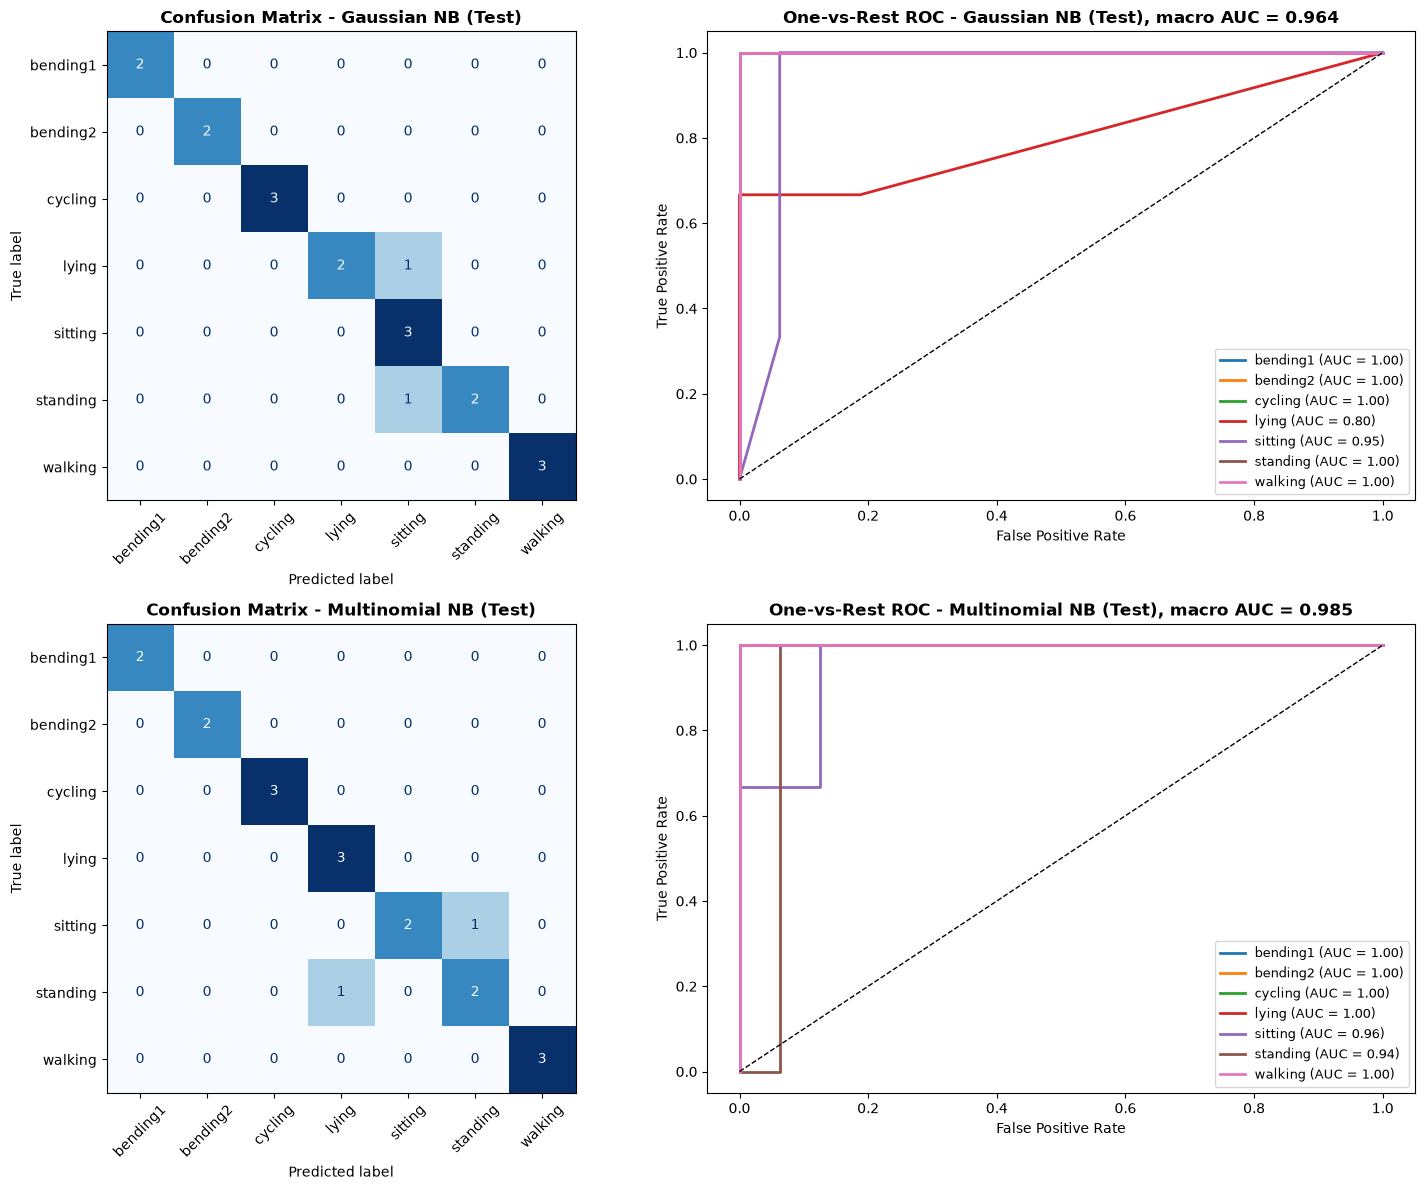

In [137]:
test1 = features[features["split"] == "test"]

X_train1 = train1.drop(columns=["label", "split", "bending"])
y_train1 = train1["label"]
X_test1 = test1.drop(columns=["label", "split", "bending"])
y_test1 = test1["label"]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for row, (name, NB) in enumerate([("Gaussian", GaussianNB), ("Multinomial", MultinomialNB)]):
    nb_model = NB().fit(X_train1, y_train1)
    preds = nb_model.predict(X_test1)
    print(f"{name} NB test error: {1 - accuracy_score(y_test1, preds):.4f}")

    classes = nb_model.classes_
    ax_cm, ax_roc = axes[row]

    # confusion matrix
    ConfusionMatrixDisplay(confusion_matrix(y_test1, preds, labels=classes),
                           display_labels=classes).plot(ax=ax_cm, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax_cm.set_title(f"Confusion Matrix - {name} NB (Test)", fontweight="bold")

    # one-vs-rest ROC
    y_te_bin = label_binarize(y_test1, classes=classes)
    probs = nb_model.predict_proba(X_test1)
    aucs = []
    for i, cls in enumerate(classes):
        fpr_i, tpr_i, _ = roc_curve(y_te_bin[:, i], probs[:, i])
        auc_i = auc(fpr_i, tpr_i)
        aucs.append(auc_i)
        ax_roc.plot(fpr_i, tpr_i, lw=2, label=f"{cls} (AUC = {auc_i:.2f})")
    ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
    ax_roc.set_xlabel("False Positive Rate"); ax_roc.set_ylabel("True Positive Rate")
    ax_roc.set_title(f"One-vs-Rest ROC - {name} NB (Test), macro AUC = {np.mean(aucs):.3f}", fontweight="bold")
    ax_roc.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

Both Naive Bayes models were selected at l = 1 by cross-validation 
- CV accuracy 0.857 for Gaussian
- CV accuracy 0.855 for Multinomial

On the test set, both achieved a test error of 0.105 (2/19 misclassified), and both classified bending1, bending2, cycling, and walking perfectly. However, they make errors on the stationary activities. 
- Gaussian NB misclassified one lying and one standing recording as sitting 
-  Multinomial NB misclassified one sitting recording as standing and one standing recording as lying

Multinomial NB had a slightly higher macro-average AUC (0.985 vs. 0.964). Overall the two performed nearly identically on this data

#### iii. Comparison

L1-penalized multinomial logistic regression is better for this multi-class classification in this problem.
It had:
- Higher CV accuracy: 0.914 vs. ~0.856 for both Naive Bayes models.
- Test error favored Naive Bayes: (0.105 vs. 0.158), but the test set is considerably small (19 recordings). CV, averaged over all 69 training recordings, is more reliable.
- Better fit to the data: Naive Bayes assumes independent features, but many here are correlated, so accuracy drops as l grows. L1 handles this by zeroing redundant features.

## 3. ISLR 4.8.3

**Step 1: Bayes' theorem** (4.15) The Bayes classifier assigns $x$ to class $k$ with largest posterior:

$$
\Pr(Y = k \mid X = x) = \frac{\pi_k \, f_k(x)}{\sum_{l=1}^{K} \pi_l \, f_l(x)}
$$

**Step 2: Normal density** (4.16) with variance that is specific for each class $\sigma_k^2$:

$$
f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left( -\frac{1}{2\sigma_k^2}(x - \mu_k)^2 \right)
$$

**Step 3: Get rid of denominator.** Dividing every class's numerator by the same positive number, does not change which numerator is biggest so maximizing the posterior is the same as maximizing the numerator:

$$
\pi_k \cdot \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left( -\frac{1}{2\sigma_k^2}(x - \mu_k)^2 \right)
$$

**Step 4: Take the log.**  Since the log is increasing, the maximizing class is not changed:

$$
\log \pi_k - \log\sqrt{2\pi} - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}
$$

$\log\sqrt{2\pi}$ is the same for every class, so we drop it:

$$
\delta_k(x) = \log \pi_k - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}
$$

**Step 5: Expand the square.**

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}x^2 + \frac{\mu_k}{\sigma_k^2}x - \left(\frac{\mu_k^2}{2\sigma_k^2} + \log \sigma_k - \log \pi_k\right)$$


**Step 6: Observe the quadratic form.** We can write $\delta_k(x) = a_k x^2 + b_k x + c_k$, where

$$
a_k = -\frac{1}{2\sigma_k^2}, \qquad b_k = \frac{\mu_k}{\sigma_k^2}, \qquad c_k = -\left(\frac{\mu_k^2}{2\sigma_k^2} + \log \sigma_k - \log \pi_k\right)
$$

The decision boundary between classes $k$ and $j$ is where $\delta_k(x) = \delta_j(x)$:

$$
(a_k - a_j)\,x^2 + (b_k - b_j)\,x + (c_k - c_j) = 0, \qquad a_k - a_j = \frac{1}{2\sigma_j^2} - \frac{1}{2\sigma_k^2}
$$

**Step 7: Conclusion.** The coefficient of $x^2$ is $\frac{1}{2\sigma_j^2} - \frac{1}{2\sigma_k^2}$, which is nonzero whenever $\sigma_k^2 \neq \sigma_j^2$. So the $x^2$ term does not cancel, and the Bayes decision boundary is **quadratic** in $x$, not linear.

In LDA, all classes share one variance $\sigma^2$, so the $x^2$ term is $-\frac{x^2}{2\sigma^2}$ for every class and cancels, and $\log\sigma_k$ is constant. That leaves a boundary linear in $x$, which is why LDA is linear and QDA is quadratic.



## 4. ISLR 4.8.7

- Mean profit for companies that issued a dividend: $\mu_{yes} = 10$
- Mean profit for companies that did NOT issue a dividend: $\mu_{no} = 0$
- Shared variance: $\sigma^2 = 36$
- Prior probability Yes: $\pi_{yes} = P(\text{yes}) = 0.8$
- Prior probability No:  $\pi_{no} = P(\text{no}) = 0.2$

**Bayes' theorem:**

$$
P(\text{yes} \mid X = 4) = \frac{\pi_{yes}\, f_{yes}(4)}{\pi_{yes}\, f_{yes}(4) + \pi_{no}\, f_{no}(4)}
$$

where density function for a normal random variable: $f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma^2}\right)$.

Since both classes share $\sigma^2 = 36$, the constant $\frac{1}{\sqrt{2\pi\sigma^2}}$ appears in every term of the numerator and denominator and cancels, so only the exponential terms are needed.

**at $x = 4$:**

$$
\exp\left(-\frac{(4 - 10)^2}{2 \cdot 36}\right) = \exp\left(-\frac{36}{72}\right) = e^{-0.5} \approx 0.6065
$$

$$
\exp\left(-\frac{(4 - 0)^2}{2 \cdot 36}\right) = \exp\left(-\frac{16}{72}\right) = e^{-0.2222} \approx 0.8007
$$

**Plug in values:**

$$
P(\text{yes} \mid X = 4) = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6453} \approx 0.752
$$


The probability that a company with last year's percentage profit of $X = 4$ will issue a dividend this year is approximately **75.2%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9